# 02 - Models, held-out evaluation, error analysis and explanation
Everything here is read from files produced by `python -m busdemand.train` (nothing is typed in by hand).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image
from busdemand import config as C
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25})
m = json.loads(C.METRICS_JSON.read_text())
preds = pd.read_csv(C.TEST_PREDS, parse_dates=["date", "departure_datetime"])
print("best model:", m["best_model"], m["best_params"][m["best_model"]])

best model: hist_gradient_boosting {'loss': 'poisson', 'learning_rate': 0.1, 'max_leaf_nodes': 31}


## 1. Split strategy

In [2]:
print(json.dumps(m["leakage_audit"]["chronological_split"], indent=1))

{
 "passed": true,
 "train": [
  "2022-01-01",
  "2025-06-30"
 ],
 "validation": [
  "2025-07-01",
  "2025-09-30"
 ],
 "test": [
  "2025-10-01",
  "2025-12-31"
 ],
 "rows": {
  "train": 87147,
  "validation": 6276,
  "test": 6269
 }
}


## 2. Validation (used for tuning/selection) vs. TEST (used once)

,val_MAE,val_RMSE,val_WAPE,test_MAE,test_RMSE,test_WAPE,test_Bias
baseline_route_time,5.352,6.788,0.205,6.249,7.843,0.209,-4.091
baseline_seasonal_naive,6.136,7.886,0.235,5.803,7.420,0.194,-1.085
ridge,5.771,7.309,0.221,5.701,7.106,0.190,-1.574
random_forest,5.363,6.803,0.205,5.265,6.532,0.176,-1.404
hist_gradient_boosting,4.987,6.382,0.191,4.941,6.175,0.165,-1.326


WAPE reduction vs route/time baseline on test: 20.9 %


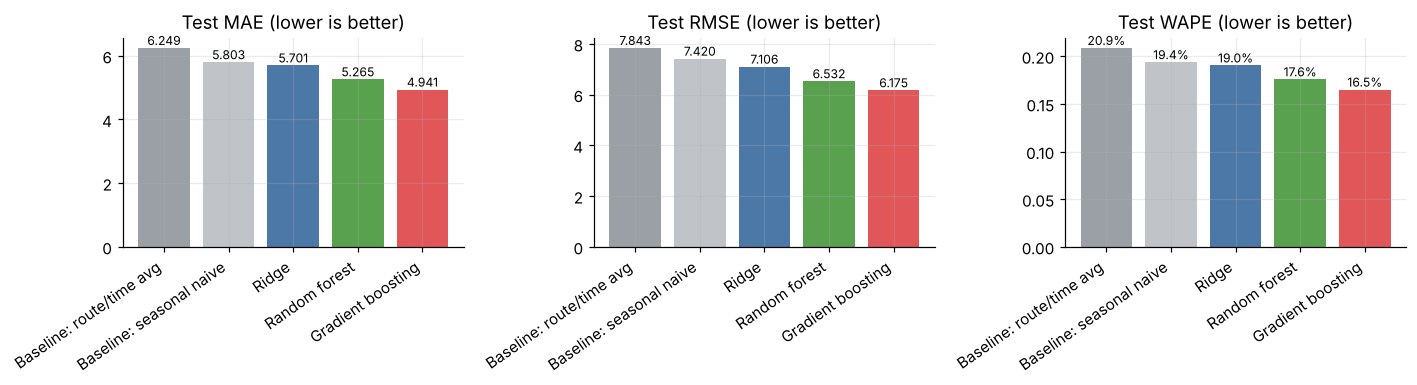

In [3]:
val = pd.DataFrame(m["validation"]).T[["MAE", "RMSE", "WAPE"]].add_prefix("val_")
tst = pd.DataFrame(m["test"]).T[["MAE", "RMSE", "WAPE", "Bias"]].add_prefix("test_")
display(val.join(tst).round(3))
print("WAPE reduction vs route/time baseline on test:", m["improvement_vs_baseline"]["relative_wape_reduction_pct"], "%")
Image(str(C.FIGURES / "res_overall_metrics.png"))

### Tuning log (validation only)

In [4]:
display(pd.DataFrame(m["tuning_log"]).sort_values(["model", "val_MAE"]).reset_index(drop=True))

,model,params,val_MAE
0,hist_gradient_boosting,"{'loss': 'poisson', 'learning_rate': 0.1, 'max...",4.9871
1,hist_gradient_boosting,"{'loss': 'squared_error', 'learning_rate': 0.1...",5.0179
2,hist_gradient_boosting,"{'loss': 'squared_error', 'learning_rate': 0.1...",5.0419
3,hist_gradient_boosting,"{'loss': 'poisson', 'learning_rate': 0.05, 'ma...",5.0429
4,hist_gradient_boosting,"{'loss': 'poisson', 'learning_rate': 0.1, 'max...",5.0546
5,hist_gradient_boosting,"{'loss': 'squared_error', 'learning_rate': 0.0...",5.0640
6,hist_gradient_boosting,"{'loss': 'poisson', 'learning_rate': 0.05, 'ma...",5.1182
7,hist_gradient_boosting,"{'loss': 'squared_error', 'learning_rate': 0.0...",5.1371
8,random_forest,"{'min_samples_leaf': 5, 'max_features': 0.5}",5.3626
9,random_forest,"{'min_samples_leaf': 20, 'max_features': 0.5}",5.4721


## 3. Error analysis - per route

,n,MAE,WAPE,Bias,baseline_MAE,baseline_WAPE
R01,549.0,4.968,0.150,-1.488,6.695,0.202
R02,637.0,4.426,0.150,-0.359,5.257,0.178
R03,543.0,4.982,0.155,-1.819,6.687,0.208
R04,455.0,5.740,0.170,-2.505,7.284,0.216
R05,546.0,4.528,0.173,-0.906,4.942,0.189
R06,541.0,5.022,0.142,-1.847,6.832,0.194
R07,548.0,4.692,0.178,-1.229,5.227,0.198
R08,451.0,5.159,0.189,-1.061,6.736,0.246
R09,363.0,5.806,0.181,-1.867,8.219,0.256
R10,548.0,4.793,0.142,-1.422,6.336,0.188


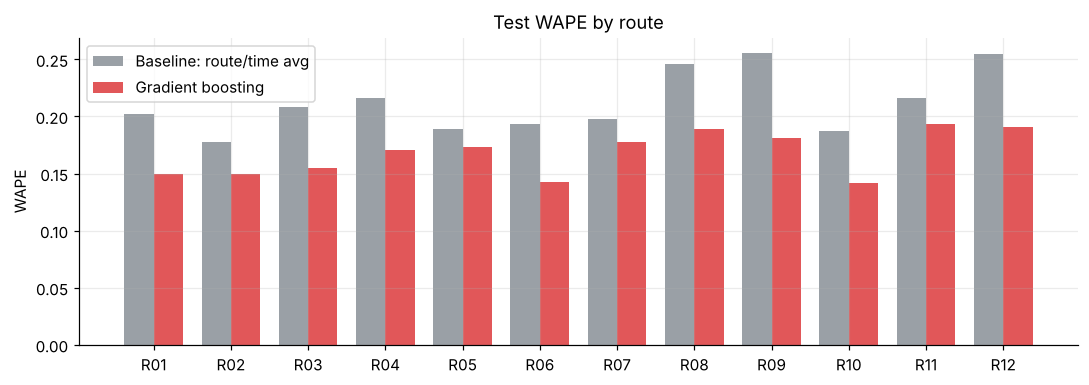

In [5]:
best = m["best_model"]
r = pd.DataFrame(m["by_route"][best]).T[["n", "MAE", "WAPE", "Bias"]].join(pd.DataFrame(m["by_route"]["baseline_route_time"]).T[["MAE", "WAPE"]].add_prefix("baseline_"))
display(r.round(3))
Image(str(C.FIGURES / "res_wape_by_route.png"))

## 4. Peak vs off-peak, day type, disruptions

by_peak


baseline_route_time                      hist_gradient_boosting                     
                           n    MAE   WAPE   Bias                      n    MAE   WAPE   Bias
off-peak              2536.0  6.063  0.230 -4.209                 2536.0  4.770  0.181 -1.415
peak                  3733.0  6.376  0.197 -4.011                 3733.0  5.058  0.156 -1.266

by_day_type


baseline_route_time                      hist_gradient_boosting                     
                          n    MAE   WAPE   Bias                      n    MAE   WAPE   Bias
holiday               272.0  7.098  0.287 -0.152                  272.0  4.915  0.199 -1.835
weekday              4222.0  6.267  0.210 -4.310                 4222.0  4.985  0.167 -1.273
weekend              1775.0  6.078  0.197 -4.174                 1775.0  4.841  0.157 -1.374

by_disruption


baseline_route_time                        hist_gradient_boosting                       
                             n     MAE   WAPE    Bias                      n     MAE   WAPE    Bias
disruption                 6.0  16.082  1.398  16.082                    6.0  16.511  1.436  16.511
normal                  6263.0   6.240  0.208  -4.111                 6263.0   4.930  0.165  -1.343

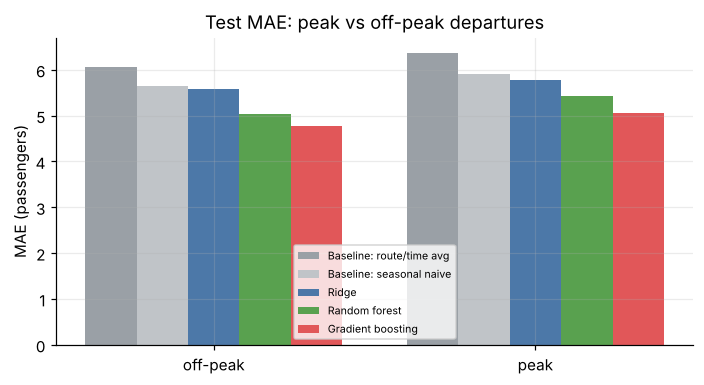

In [6]:
for key in ["by_peak", "by_day_type", "by_disruption"]:
    print(key)
    display(pd.concat({k: pd.DataFrame(m[key][k]).T[["n", "MAE", "WAPE", "Bias"]] for k in ["baseline_route_time", best]}, axis=1).round(3))
Image(str(C.FIGURES / "res_peak_offpeak.png"))

**Reading the bias column:** negative bias means under-forecasting. The baseline under-forecasts by ~4 passengers (it cannot see growth, seasonality or holidays); the model cuts the bias to ~1.3. Under-forecasting is the costly direction for capacity planning, so we also look at flags below.

## 5. Capacity-aware flags (business metric)

In [7]:
rows = []
for k, d in m["test_flag_metrics"].items():
    for rule, v in d.items():
        rows.append({"method": k, "flag rule": rule, "precision": v["precision"], "recall": v["recall"], "f1": v["f1"], "flagged": v["flagged"], "actually full": v["actual_positive"]})
display(pd.DataFrame(rows).round(3))

,method,flag rule,precision,recall,f1,flagged,actually full
0,baseline_route_time,HIGH (pred occ>=90%),0.843,0.081,0.147,127,1325
1,baseline_route_time,WATCH+HIGH (pred occ>=75%),0.611,0.524,0.564,1135,1325
2,baseline_seasonal_naive,HIGH (pred occ>=90%),0.623,0.294,0.399,624,1325
3,baseline_seasonal_naive,WATCH+HIGH (pred occ>=75%),0.460,0.729,0.564,2100,1325
4,ridge,HIGH (pred occ>=90%),0.742,0.152,0.252,271,1325
5,ridge,WATCH+HIGH (pred occ>=75%),0.518,0.656,0.579,1679,1325
6,random_forest,HIGH (pred occ>=90%),0.787,0.123,0.213,207,1325
7,random_forest,WATCH+HIGH (pred occ>=75%),0.525,0.752,0.618,1899,1325
8,hist_gradient_boosting,HIGH (pred occ>=90%),0.807,0.250,0.382,410,1325
9,hist_gradient_boosting,WATCH+HIGH (pred occ>=75%),0.548,0.783,0.645,1892,1325


*Event to catch = a trip that actually ends up >= 90 % full.* The 75 % WATCH rule is fixed a priori (not tuned on test). It trades some false alarms for much higher recall, which is the right trade-off when an empty extra bus costs less than turning passengers away.

## 6. Uncertainty: 80 % prediction interval (split conformal)

target coverage 80% -> empirical TEST coverage: 0.799 | 90% -> 0.911 | mean width (80%): 15.3 passengers


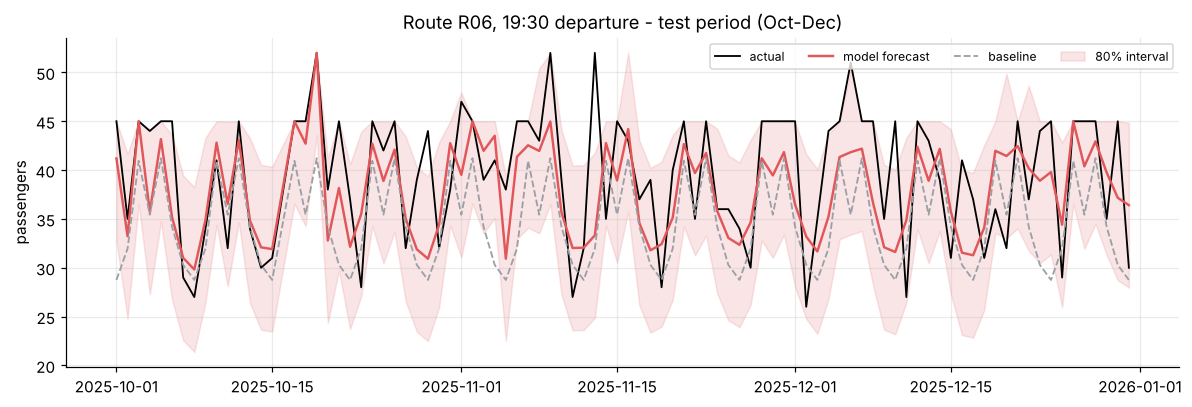

In [8]:
iv = m["interval"]
print("target coverage 80% -> empirical TEST coverage:", round(iv["test_coverage_80"], 3), "| 90% ->", round(iv["test_coverage_90"], 3), "| mean width (80%):", round(iv["avg_width_80"], 1), "passengers")
Image(str(C.FIGURES / "res_timeseries_example.png"))

## 7. What drives the forecast? (global)

,meaning,mae_increase
0,average same-slot demand (last 4 same weekdays),1.906
1,route distance,1.141
2,day of week,0.740
3,peak-hour departure,0.659
4,days until next holiday,0.453
5,departure time of day,0.448
6,weekend,0.255
7,"route's average occupancy, last 28 days",0.198
8,route,0.167
9,public holiday,0.160


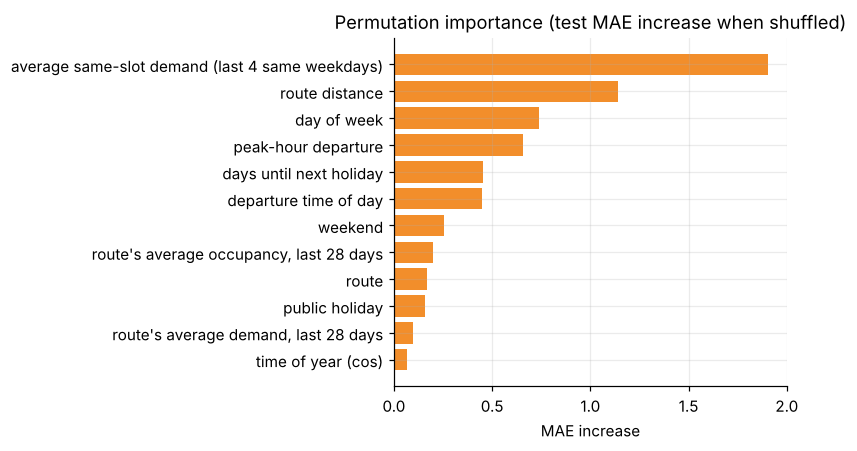

In [9]:
display(pd.DataFrame(m["importance"])[["meaning", "mae_increase"]].round(3))
Image(str(C.FIGURES / "res_importance.png"))

## 8. Explaining individual predictions and errors

In [10]:
for e in m["examples"]:
    print(f"\n=== {e['tag']} | {e['trip_id']} | actual={e['actual']} predicted={e['predicted']} baseline={e['baseline_prediction']} | disruption: {e['disruption_known_to_generator']}")
    display(pd.DataFrame(e["drivers"])[["meaning", "value", "typical_value", "impact_passengers"]])


=== typical_prediction | R07-20251125-1700 | actual=33.0 predicted=28.8 baseline=27.5 | disruption: False


,meaning,value,typical_value,impact_passengers
0,departure time of day,17.0,12.5,3.05
1,season,post_monsoon,summer,1.85
2,average same-slot demand (last 4 same weekdays),30.25,25.75,1.53
3,average same-slot occupancy (last 4 same weekd...,0.74,0.576,-1.49
4,time of year (sin),-0.584,0.171,-0.85
5,route distance,65.0,220.0,0.75



=== largest_error_without_disruption | R08-20251225-1200 | actual=45.0 predicted=20.9 baseline=15.1 | disruption: False


,meaning,value,typical_value,impact_passengers
0,time of year (sin),-0.107,0.171,7.39
1,average same-slot demand (last 4 same weekdays),17.000,25.750,-5.48
2,public holiday,1.000,0.000,2.14
3,days until next holiday,7.000,10.000,1.46
4,peak-hour departure,0.000,1.000,-1.10
5,same-slot demand 5 weeks ago,13.000,25.000,0.63



=== largest_error_during_disruption | R02-20251119-0730 | actual=9.0 predicted=32.7 baseline=31.8 | disruption: True


,meaning,value,typical_value,impact_passengers
0,average same-slot demand (last 4 same weekdays),30.75,25.75,3.68
1,"route's average occupancy, last 28 days",0.736,0.589,2.39
2,departure time of day,7.5,12.5,2.36
3,average same-slot occupancy (last 4 same weekd...,0.769,0.576,-2.33
4,route,R02,R11,2.05
5,route distance,100.0,220.0,1.59


**How to read this:** *impact_passengers* = change in the forecast if that input were replaced by its typical training value (an approximation without interaction effects). For the largest non-disruption error (Christmas Day on the Chandigarh-Shimla tourist route) the model forecasts ~21 but 45 board: holidays on tourist routes are rare in training (one Christmas per year) and the trip is sold out, so the model under-reacts. For the disruption example (R02, a strike day) the model sees normal history and cannot know about the strike.

## 9. Worst errors table

In [11]:
cols = ["trip_id", "y", "pred", "pred_baseline_route_time", "abs_err", "day_type", "disruption_label"]
display(preds.sort_values("abs_err", ascending=False)[cols].head(10).round(1))
print("Share of total absolute error from the worst 5% of trips:", round(preds.abs_err.sort_values(ascending=False).head(int(len(preds) * .05)).sum() / preds.abs_err.sum(), 3))

,trip_id,y,pred,pred_baseline_route_time,abs_err,day_type,disruption_label
5823,R08-20251225-1200,45.0,20.9,15.1,24.1,holiday,normal
3350,R02-20251119-0730,9.0,32.7,31.8,23.7,weekday,disruption
5681,R12-20251223-1030,43.0,20.0,14.0,23.0,weekday,normal
5475,R12-20251220-1030,52.0,29.2,26.2,22.8,weekend,normal
3357,R02-20251119-0900,11.0,33.6,32.3,22.6,weekday,disruption
5182,R09-20251216-0600,45.0,23.8,22.8,21.2,weekday,normal
3756,R04-20251125-0630,43.0,22.3,22.6,20.7,weekday,normal
3384,R02-20251119-1700,13.0,33.3,32.4,20.3,weekday,disruption
5218,R04-20251216-1600,45.0,24.8,27.1,20.2,weekday,normal
1525,R02-20251023-1200,39.0,19.6,18.5,19.4,weekday,normal


Share of total absolute error from the worst 5% of trips: 0.146


## 10. Live inference through the saved artifact

In [12]:
from busdemand.predict import DemandPredictor
p = DemandPredictor()
r = p.predict("R01", "2025-12-24 18:00")
print({k: r[k] for k in ["route", "predicted_passengers", "interval_low", "interval_high", "predicted_occupancy", "capacity_flag", "sell_out_risk", "actual_passengers_for_comparison", "warnings"]})

{'route': 'Chandigarh - Delhi', 'predicted_passengers': 40.3, 'interval_low': 31.9, 'interval_high': 45.0, 'predicted_occupancy': 0.896, 'capacity_flag': 'ELEVATED', 'sell_out_risk': True, 'actual_passengers_for_comparison': 45.0, 'warnings': []}


## Conclusions
* The tuned gradient-boosting model beats the historical route/time baseline on every metric overall and on every route and in peak and off-peak periods.
* Error is largest for rare events (festivals on tourist routes) and unforecastable disruptions: the tool says so via warnings, wider intervals and the human-review requirement.
* Limits: synthetic data, single test window (Oct-Dec 2025), 6 disruption trips in test (too few for a firm estimate), no real booking-curve features.